# Chapter 22 | Complete worked solutions

*Image and Video Understanding*

All twelve exercises are solved here. Begin with shapes, preprocessing and
attention counts, then trace real array values, train small linear probes,
and design evaluation protocols. The examples run on CPU without downloads.
The image features and numeric fixtures are deliberately small; they are not
benchmarks of pretrained vision models. The written PDF preserves every
explanation and both plots; the notebook PDF also includes code and outputs.

In [1]:
from pathlib import Path
import sys

import numpy as np

working_directory = Path.cwd()
for repo_root in (working_directory, *working_directory.parents):
    model_path = (
        repo_root / "examples" / "ch22_vision"
    )
    if model_path.is_dir():
        sys.path.insert(0, str(repo_root))
        break
else:
    raise FileNotFoundError(
        "Open this notebook inside transformers-book."
    )

import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
from examples.ch22_vision.model import space_time_pairs
print("NumPy", np.__version__, "| Matplotlib", matplotlib.__version__)

NumPy 2.5.4 | Matplotlib 3.11.2


## 1. Make a patch grid

The image has 12 rows and 8 columns. A patch spans four rows and four
columns, so there are $12/4=3$ patch rows and $8/4=2$ patch columns.
This gives six patches. Each contains $4\times4\times3=48$ channel values.

Flattening only rearranges those values into a row. Stacking the six rows
gives shape $[6,48]$. Multiplying by a shared projection of shape $[48,5]$
gives $[6,5]$. One classification row gives the final shape $[7,5]$; its
position array must also have shape $[7,5]$. No batch axis is shown.

A linear projection from 48 dimensions to five cannot distinguish every
possible real-valued patch: different inputs can map to the same output.
Flattening does not have this limitation because it can be reversed exactly
when the original dimensions and order are known. The classification row is
a learned summary position, not another observed image patch.

In [2]:
height,width,channels,patch,dim=12,8,3,4,5
n=(height//patch)*(width//patch)
flat_width=patch*patch*channels
assert (n,flat_width)==(6,48)
print("Patch matrix:",(n,flat_width))
print("Projection:",(flat_width,dim))
print("Encoder input:",(n+1,dim))

Patch matrix: (6, 48)
Projection: (48, 5)
Encoder input: (7, 5)


## 2. Change the patch size

For a $32\times32$ image, patches of side eight give a $4\times4$ grid,
so $N=16$ and the full patch-only score matrix has $16^2=256$ entries.
Patches of side four give an $8\times8$ grid, so $N=64$ and $64^2=4096$.
The token count grows fourfold; the score count grows sixteenfold.

A smaller patch lets attention address smaller regions separately. Two
objects that previously fell inside one token can occupy different tokens.
This does not guarantee a better classifier. Pixel evidence, the projection,
training, and task all matter. Nor is this a sixteenfold claim about total
runtime: projections and feed-forward layers have other costs. Adding a
classification token would give $17^2=289$ and $65^2=4225$ scores, so the
exact sixteenfold ratio applies only to the patch-only count requested.

In [3]:
for side in (8,4):
    count=(32//side)**2
    print(f"Patch side {side}: {count} tokens, {count**2} patch scores")
assert 4096//256==16 and 64//16==4

Patch side 8: 16 tokens, 256 patch scores
Patch side 4: 64 tokens, 4096 patch scores


## 3. Check an input convention

First match the pixel scale: $153/255=0.6$. Then apply the channel's
normalization: $(0.6-0.5)/0.25=0.4$. Skipping the first operation gives
$(153-0.5)/0.25=610$, an entirely different input.

The mean and standard deviation are meaningful on their specified scale.
Use the checkpoint's own preprocessing; the example statistics are not
universal. Two other choices to match are channel order, such as RGB rather
than BGR, and the resize/crop procedure including its target dimensions.
A correct numerical range cannot restore an object that a crop removed.
Interpolation and padding conventions can matter as well.

In [4]:
scaled=153/255
normalized=(scaled-.5)/.25
wrong=(153-.5)/.25
np.testing.assert_allclose([scaled,normalized,wrong],[.6,.4,610])
print(f"Scaled: {scaled:.1f}; normalized: {normalized:.1f}; skipped rescaling: {wrong:.0f}")

Scaled: 0.6; normalized: 0.4; skipped rescaling: 610


## 4. Count video connections

There are $T=4$ frames and $S=9$ patches per frame, so the clip has
$TS=36$ patch tokens. Joint attention has $36^2=1296$ ordered query-key
scores per head. Temporal attention has nine groups of four tokens,
$9\times4^2=144$ scores. Spatial attention has four groups of nine tokens,
$4\times9^2=324$ scores. Their sum is 468. These counts include self-pairs
in each operation and exclude special tokens.

One temporal group is $(1,2)$, $(2,2)$, $(3,2)$, $(4,2)$, with frame index first.
One spatial group is $(4,1)$ through $(4,9)$. The desired route is
input $(1,2)$ to the temporally mixed output at $(4,2)$, then to the
spatially mixed output at $(4,7)$. Each arrow carries information from
a value source into a receiving output. The intermediate token belongs
to a new stage, not to the original input array. This possible route
explains reachability; it does not make two operations equal to joint
attention or guarantee a large learned weight on that route.

In [5]:
counts=space_time_pairs(4,9)
assert counts["joint"]==1296
assert counts["temporal"]==144 and counts["spatial"]==324
print(counts)
print("Temporal group:",[(t,2) for t in range(1,5)])
print("Spatial group:",[(4,s) for s in range(1,10)])
print("Route: input (1,2) -> temporal output (4,2) -> spatial output (4,7)")

{'joint': 1296, 'spatial': 324, 'temporal': 144, 'divided': 468}
Temporal group: [(1, 2), (2, 2), (3, 2), (4, 2)]
Spatial group: [(4, 1), (4, 2), (4, 3), (4, 4), (4, 5), (4, 6), (4, 7), (4, 8), (4, 9)]
Route: input (1,2) -> temporal output (4,2) -> spatial output (4,7)


## 5. Check row-major patch order

Fill a four-row, six-column image with the integers 0 through 23.
Each pixel has one channel. Think of the values as labels for the
pixels. They let us trace each entry in a flattened patch back to
its original location. A side length of two gives two patch rows
and three patch columns. Each patch contributes four values, so
the output should have shape $(6,4)$.

In [6]:
from examples.ch22_vision.model import patchify

image = np.arange(24).reshape(4, 6, 1)
patch_rows = patchify(image, patch_size=2)

print("Image values (channel 0)")
print(image[:, :, 0])
print("Flattened patches (one patch per row)")
print(patch_rows)

Image values (channel 0)
[[ 0  1  2  3  4  5]
 [ 6  7  8  9 10 11]
 [12 13 14 15 16 17]
 [18 19 20 21 22 23]]
Flattened patches (one patch per row)
[[ 0  1  6  7]
 [ 2  3  8  9]
 [ 4  5 10 11]
 [12 13 18 19]
 [14 15 20 21]
 [16 17 22 23]]


**Row-major** means `patchify` visits the three patches across the
top before moving to the bottom. It also reads the pixels within
each patch across the first row, then across the second. The first
output row comes from the upper-left patch, and the last comes from
the lower-right patch. With zero-based image coordinates and the
single channel fixed at 0, the entries map back as follows.

| Output row | Pixel value | Image row | Image column |
| --- | ---: | ---: | ---: |
| First | 0 | 0 | 0 |
| First | 1 | 0 | 1 |
| First | 6 | 1 | 0 |
| First | 7 | 1 | 1 |
| Last | 16 | 2 | 4 |
| Last | 17 | 2 | 5 |
| Last | 22 | 3 | 4 |
| Last | 23 | 3 | 5 |

The value at image row $r$ and column $c$ is $6r+c$ because each
preceding image row contains six pixels. To check the ordering
independently, we can read all six patches directly by their
upper-left corners and compare the four entries in each row. A
shape check alone would also pass if the patch rows were shuffled.

In [7]:
expected_patches = []
for row in (0, 2):
    for column in (0, 2, 4):
        expected_patches.append([
            image[row, column, 0],
            image[row, column + 1, 0],
            image[row + 1, column, 0],
            image[row + 1, column + 1, 0],
        ])

assert patch_rows.shape == (6, 4)
np.testing.assert_array_equal(patch_rows, expected_patches)

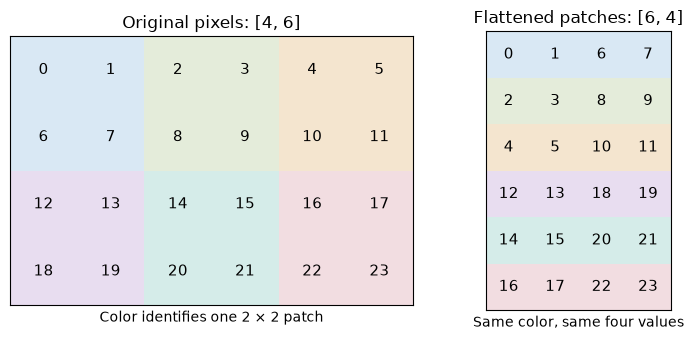

In [8]:
fig,axes=plt.subplots(1,2,figsize=(8,3.5))
palette=np.array(["#D9E8F4","#E4ECDA","#F4E5CF","#E8DDF0","#D5ECE9","#F2DDE1"])
from matplotlib.colors import ListedColormap
regions=np.repeat(np.repeat(np.arange(6).reshape(2,3),2,axis=0),2,axis=1)
axes[0].imshow(regions,cmap=ListedColormap(palette),vmin=0,vmax=5)
axes[1].imshow(np.repeat(np.arange(6)[:,None],4,axis=1),cmap=ListedColormap(palette),vmin=0,vmax=5)
for ax,values,title in zip(axes,[image[:,:,0],patch_rows],["Original pixels: [4, 6]","Flattened patches: [6, 4]"]):
    for (rr,cc),value in np.ndenumerate(values):
        ax.text(cc,rr,str(value),ha="center",va="center",fontsize=11)
    ax.set_title(title);ax.set_xticks([]);ax.set_yticks([])
axes[0].set_xlabel("Color identifies one 2 × 2 patch")
axes[1].set_xlabel("Same color, same four values")
fig.tight_layout();plt.show()

Each colored region on the left becomes one row on the right. The first
row is 0, 1, 6, 7 and the last is 16, 17, 22, 23. The figure traces
values, rather than merely checking that both arrays contain 24 entries.

## 6. Add a position to an identical patch

Give two patches the same four input values, $(1,2,3,4)$. A
projection turns each length-four row into a length-two token by
multiplying it by the same weight matrix. We choose the first
column of the matrix to add the first and third values, and the
second column to subtract the fourth value from the second.

$$
(1,2,3,4)
\begin{bmatrix}1&0\\0&1\\1&0\\0&-1\end{bmatrix}
= (1+3,\, 2-4) = (4,-2).
$$

Each output coordinate is a dot product with one column of the
matrix. The two input rows are identical, so both dot products
give the same results for each row. Call `patch_embeddings` without
a classification token. Both calls therefore return a $(2,2)$
array, with one row per patch and one column per output coordinate.

In [9]:
from examples.ch22_vision.model import patch_embeddings

identical_patches = np.array([[1, 2, 3, 4], [1, 2, 3, 4]])
projection = np.array([[1, 0], [0, 1], [1, 0], [0, -1]])
positions = np.array([[0, 0], [0, 1]])

default_tokens = patch_embeddings(identical_patches, projection)
positioned_tokens = patch_embeddings(
    identical_patches, projection, positions=positions
)

print("Default tokens")
print(default_tokens)
print("Tokens with position vectors")
print(positioned_tokens)

Default tokens
[[ 4. -2.]
 [ 4. -2.]]
Tokens with position vectors
[[ 4. -2.]
 [ 4. -1.]]


`positions` supplies an additive vector for each token row. Adding
$(0,0)$ leaves the first row at $(4,-2)$. Adding $(0,1)$ changes the
second row to $(4,-1)$.

More generally, let $z$ be the shared projected patch and $p_1$
and $p_2$ be any two position vectors of the same width. The
returned rows are $z+p_1$ and $z+p_2$. Subtracting the first row
from the second cancels $z$ and gives $p_2-p_1$. Adding the same
shift to both positions moves both tokens by that amount and
preserves their difference. The exercise chooses the two vectors
by hand to make this operation easy to see. In the chapter's
Vision Transformer, training learns a position vector for each
location.

In [10]:
# Check the full arrays against the hand calculation.
np.testing.assert_array_equal(default_tokens, [[4, -2], [4, -2]])
np.testing.assert_array_equal(positioned_tokens, [[4, -2], [4, -1]])
np.testing.assert_array_equal(
    positioned_tokens[1] - positioned_tokens[0], [0, 1]
)

The rows differ because different position vectors were added to the
same content vector. Simply placing identical vectors in two rows would
not make them different. More generally, in deterministic full self-attention
with shared tokenwise operations and no position-dependent mechanism,
permuting patch rows permutes their outputs. A classification token kept
in place has the same output. Fixed location vectors break this symmetry
when content moves relative to them. Permuting content together with its
position vectors only relabels the rows again. A mask or other mechanism
that depends on position changes the assumptions of this argument.

## 7. Compare ordered and sorted features

The four features give the brightness at the upper left, upper
right, lower left, and lower right, in that order. Class 0 has
its bright patch in the top row and class 1 has it in the bottom row. For example,
$(1,0,0,0)$ and $(0,0,1,0)$ place the same brightness in different
rows. An ordered head can separate the classes by comparing the
sum of the two upper features with the sum of the two lower ones.

Fit a **linear probe**, a classifier that learns weights and
biases while keeping the input features fixed. Both fits use four
input features, two class scores, 120 training steps and a learning
rate of 0.5. The second fit sorts values within each row, preserving
which brightness values appear while discarding their locations.
The labels stay attached to the same training examples.

In [11]:
from examples.ch22_vision.model import train_linear_probe

ordered = np.array([
    [1, 0, 0, 0],
    [0, 0, 1, 0],
    [0, 2, 0, 0],
    [0, 0, 0, 2],
])
labels = np.array([0, 1, 0, 1])
sorted_rows = np.sort(ordered, axis=1)
settings = {"steps": 120, "lr": 0.5}
ordered_weight, ordered_bias = train_linear_probe(
    ordered, labels, **settings
)
sorted_weight, sorted_bias = train_linear_probe(
    sorted_rows, labels, **settings
)

print("Sorted feature rows")
print(sorted_rows)
np.testing.assert_array_equal(
    sorted_rows, [[0, 0, 0, 1], [0, 0, 0, 1],
                  [0, 0, 0, 2], [0, 0, 0, 2]]
)
np.testing.assert_array_equal(labels[::2], 1 - labels[1::2])

Sorted feature rows
[[0 0 0 1]
 [0 0 0 1]
 [0 0 0 2]
 [0 0 0 2]]


Multiply the feature rows by the fitted weight matrix and add
the bias to get two raw scores, or *logits*, for each example.
Column 0 scores class 0 and column 1 scores class 1. Choose the
larger score on each row. When two scores tie, NumPy's
`argmax` returns the first index, which here is class 0.

In [12]:
ordered_scores = ordered @ ordered_weight + ordered_bias
sorted_scores = sorted_rows @ sorted_weight + sorted_bias
ordered_predictions = ordered_scores.argmax(axis=1)
sorted_predictions = sorted_scores.argmax(axis=1)

print(
    f"{'Label':>5}  {'Ordered scores':^16}  {'Class':>5}"
    f"  {'Sorted scores':^16}  {'Class':>5}"
)
for row, label in enumerate(labels):
    score0, score1 = ordered_scores[row]
    sorted0, sorted1 = sorted_scores[row]
    print(
        f"{label:>5}  ({score0:6.3f}, {score1:6.3f})"
        f"  {ordered_predictions[row]:>5}"
        f"  ({sorted0:6.3f}, {sorted1:6.3f})"
        f"  {sorted_predictions[row]:>5}"
    )
ordered_correct = np.count_nonzero(ordered_predictions == labels)
sorted_correct = np.count_nonzero(sorted_predictions == labels)
print(f"Ordered correct {ordered_correct} of {len(labels)}")
print(f"Sorted correct  {sorted_correct} of {len(labels)}")

upper = ordered[:, :2].sum(axis=1)
lower = ordered[:, 2:].sum(axis=1)
np.testing.assert_array_equal(ordered_predictions, lower > upper)
np.testing.assert_array_equal(sorted_scores, np.zeros((4, 2)))
np.testing.assert_array_equal(sorted_predictions, [0, 0, 0, 0])

Label   Ordered scores   Class   Sorted scores    Class
    0  ( 1.666, -1.666)      0  ( 0.000,  0.000)      0
    1  (-1.666,  1.666)      1  ( 0.000,  0.000)      0
    0  ( 2.387, -2.387)      0  ( 0.000,  0.000)      0
    1  (-2.387,  2.387)      1  ( 0.000,  0.000)      0
Ordered correct 4 of 4
Sorted correct  2 of 4


The ordered head predicts $(0,1,0,1)$ and gets all four rows
right. In the sorted fit, each distinct input occurs once with
each label. The head starts with zero weights and biases, so both
classes start with probability $1/2$. The two examples in each
pair give equal and opposite updates because their features are
identical and their labels differ. The updates cancel at every
step, leaving scores $(0,0)$ on all four rows. The tie rule
gives predictions $(0,0,0,0)$ and two correct answers.

The pairwise limit holds for **any deterministic classifier**
using only these sorted inputs. A brightness of 1 can still be
distinguished from a brightness of 2, but both examples with
the same brightness must receive the same prediction. Each pair
contains one example of each class, so exactly one prediction
per pair is correct regardless of the chosen class.

These are predictions on the four rows used for fitting.
The chapter's separate synthetic-image experiment evaluates
generalization to held-out brightness and background settings.
There the ordered head gets 8 of 8 and the sorted head gets
4 of 8.

The four coordinates in this exercise are fixed spatial features read
by separate head weights. They are not patch tokens passed through a
position-free ViT. Equal feature counts and equal head capacities isolate
the information loss caused by sorting. These predictions are on the four
training rows; the companion runner separately uses 12 training and eight
held-out synthetic images, obtaining 8/8 versus 4/8 on the held-out set.

## 8. Trade temporal for spatial tokens (optional)

A token has a frame index and a patch location within that frame.
Joint attention can score a query token against every key token in
the clip. Divided attention first scores tokens at the same patch
location across frames, then scores tokens in the same frame
across patch locations.

Count one entry per ordered query and key pair, per attention
head. Include a token's score against itself and exclude special
tokens. A pair from token A to token B and the reverse pair occupy
separate entries. A token's self-score appears once in each of the
two divided operations.

With $T$ frames and $S$ patches per frame, the clip has $TS$
tokens. There are $S$ temporal groups of size $T$ and $T$ spatial
groups of size $S$, so the counts are

$$
\begin{aligned}
\text{Joint} &= (TS)^2,\\
\text{Temporal} &= S T^2,\\
\text{Spatial} &= T S^2,\\
\text{Divided} &= S T^2 + T S^2 = TS(T+S).
\end{aligned}
$$

For example, $(T,S)=(2,12)$ has 12 temporal groups with $2^2$
entries each and two spatial groups with $12^2$ entries each.
Check the function by explicitly counting the pairs of token
coordinates that each operation scores.

In [13]:
from itertools import product

from examples.ch22_vision.model import space_time_pairs

comparisons = []
for frames, patches in [(2, 12), (4, 6), (6, 4)]:
    counts = space_time_pairs(frames, patches)
    tokens = list(product(range(frames), range(patches)))
    pairs = list(product(tokens, repeat=2))
    temporal = sum(
        query[1] == key[1] for query, key in pairs
    )
    spatial = sum(
        query[0] == key[0] for query, key in pairs
    )
    assert len(tokens) == 24
    assert counts == {
        "joint": len(pairs),
        "temporal": temporal,
        "spatial": spatial,
        "divided": temporal + spatial,
    }
    comparisons.append((frames, patches, len(tokens), counts))

In [14]:
print("Frames  Patches/frame  Tokens  Joint  Temporal  Spatial  Divided")
for frames, patches, total_tokens, counts in comparisons:
    print(
        f"{frames:>6}  {patches:>13}  {total_tokens:>6}"
        f"  {counts['joint']:>5}  {counts['temporal']:>8}"
        f"  {counts['spatial']:>7}  {counts['divided']:>7}"
    )

Frames  Patches/frame  Tokens  Joint  Temporal  Spatial  Divided
     2             12      24    576        48      288      336
     4              6      24    576        96      144      240
     6              4      24    576       144       96      240


Every clip has 24 tokens and $24^2=576$ joint scores. The
divided count drops from $24(2+12)=336$ to $24(4+6)=240$ as the
group sizes become closer. Swapping 4 and 6 interchanges the
temporal and spatial counts, 96 and 144, but their sum stays 240.
Both $TS$ and $T+S$ are unchanged by the swap. The two operations
still group the tokens along different axes, so the equal totals
describe the number of entries each block scores.

Writing $N=TS$, the divided count is $ST^2+TS^2=N(T+S)$.
Dividing by the joint count $N^2$ gives $1/T+1/S$. For the three grids
the ratios are $7/12$, $5/12$, and $5/12$. With a fixed product $TS$,
balancing the two dimensions reduces their sum; swapping the dimensions
preserves it. A frame and a patch location still represent different things.
Equal counts do not imply equal information, predictions, or runtime.

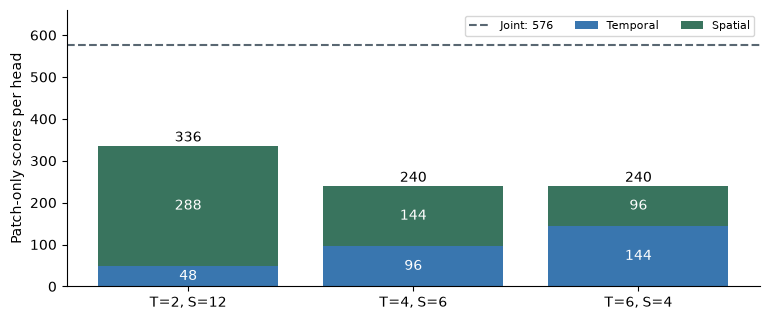

In [15]:
fig,ax=plt.subplots(figsize=(7.8,3.3))
labels_grid=["T=2, S=12","T=4, S=6","T=6, S=4"]
temporal=[c[3]["temporal"] for c in comparisons]
spatial=[c[3]["spatial"] for c in comparisons]
x=np.arange(3)
ax.bar(x,temporal,label="Temporal",color="#3976AF")
ax.bar(x,spatial,bottom=temporal,label="Spatial",color="#39745E")
ax.axhline(576,color="#596772",linestyle="--",label="Joint: 576")
for j,(t,s) in enumerate(zip(temporal,spatial)):
    ax.text(j,t/2,str(t),ha="center",va="center",color="white")
    ax.text(j,t+s/2,str(s),ha="center",va="center",color="white")
    ax.text(j,t+s+10,str(t+s),ha="center")
ax.set(xticks=x,xticklabels=labels_grid,ylim=(0,660),ylabel="Patch-only scores per head")
ax.legend(loc="upper right",ncol=3,fontsize=8)
ax.spines[["top","right"]].set_visible(False)
fig.tight_layout();plt.show()

Blue and green portions count the two divided operations, including
self-pairs in each. All three clips contain 24 tokens, so their joint
count is the same dashed reference. The first divided total is 336;
the other two are 240. The bars measure scores, not elapsed time.

## 9. Form tubelets (optional)

Six frames divided into groups of two give three temporal groups.
An $8\times12$ frame divided into $4\times4$ patches gives two patch
rows and three patch columns. Thus $3\times2\times3=18$ tubelets cover
the clip. Each contains $2\times4\times4\times3=96$ RGB channel values.

Taking patches separately from each frame gives $6\times2\times3=36$
tokens, each starting with 48 values. The tubelets halve the token count
but double the input width of each token's projection. Both constructions
account for $18\times96=36\times48=1728$ channel values before projection.
The tubelet projection sees two frames together; it need not discard all
order information, because those frames occupy distinct input coordinates.
A narrower output can still lose information. Fewer tokens alone do not
establish equal quality or a proportional saving in total compute.

In [16]:
tubelets=(6//2)*(8//4)*(12//4)
width_tubelet=2*4*4*3
frame_patches=6*(8//4)*(12//4)
assert (tubelets,width_tubelet,frame_patches)==(18,96,36)
assert tubelets*width_tubelet==frame_patches*48==1728
print(f"Tubelets: {tubelets} tokens × {width_tubelet} values")
print(f"Frame patches: {frame_patches} tokens × 48 values")

Tubelets: 18 tokens × 96 values
Frame patches: 36 tokens × 48 values


## 10. Find a leaking split (optional)

Split original recordings before making overlapping clips. For example,
assign R1-R7 to training, R8 to validation, and R9-R10 to test. With three
clips per recording, these contain 21, 3, and 6 clips. Keep all augmentations,
crops and derived clips with their parent recording. Verify that parent IDs
are disjoint. Randomly splitting the 30 clips could put nearly identical
frames on both sides and reward familiarity with a scene or actor.

For generalization to new cameras, group by camera as well. Suppose camera
A supplies R1-R4, B supplies R5-R7, C supplies R8, and D supplies R9-R10.
Train on A and B, validate on C, and test on D. This example has the same
clip counts, but its unit of exclusion is stronger. New recordings from
camera A do not constitute a test on a new camera. If people or locations
cross camera groups and must also be unseen, define groups that prevent
those overlaps too.

Choose the aggregation rule and tuning decisions using validation only.
For example, average clip probabilities within each recording and score
one recording prediction. Report class counts and per-class recall. With
only two test recordings and one test camera, conclusions about generalization
are necessarily limited; more clips do not create more independent cameras.
Uncertainty calculations should respect the independent sampling unit.
The following fixture checks split membership, not classifier performance.

In [17]:
splits={"train":set(range(1,8)),"validation":{8},"test":{9,10}}
assert not (splits["train"] & splits["validation"])
assert not (splits["train"] & splits["test"])
assert not (splits["validation"] & splits["test"])
cameras={r:("A" if r<=4 else "B" if r<=7 else "C" if r==8 else "D") for r in range(1,11)}
camera_sets={name:{cameras[r] for r in ids} for name,ids in splits.items()}
assert not (camera_sets["train"] & camera_sets["test"])
for name,ids in splits.items():
    print(name,":",len(ids),"recordings,",3*len(ids),"clips; cameras",sorted(camera_sets[name]))

train : 7 recordings, 21 clips; cameras ['A', 'B']
validation : 1 recordings, 3 clips; cameras ['C']
test : 2 recordings, 6 clips; cameras ['D']


## 11. Test an action's direction (optional)

Use opening versus closing a drawer. Select eight frames that visibly cover
the action, and pair them with the same frames in reverse order. Verify
that reversal really changes the intended label; ambiguous pauses and edits
should not be relabeled mechanically. Keep the pair in one recording group
when splitting. Include naturally recorded examples of both actions so the
experiment does not only distinguish artifacts of reversed footage.

Use the same frozen frame encoder, preprocessing and eight sampled frames
for both systems. The baseline averages its per-frame class scores. The
comparison model processes frame features with temporal attention and
temporal position embeddings. Retrain its head and temporal component on
the training split, choose settings on validation, and report their additional
parameters and cost. A separate order ablation can remove temporal position
information or shuffle frames, but neither alone proves how a trained model
uses order.

For any deterministic frame scoring function $f$,
$$
\frac18\sum_{t=1}^8 f(x_t)=\frac18\sum_{t=1}^8 f(x_{9-t}).
$$
Thus the averaged-image baseline makes the same prediction for both members.
On balanced opposite-label pairs its clip accuracy is exactly one half for
a binary forced-choice classifier, and its pair accuracy is zero. Pair
accuracy counts a pair correct only when both labels are correct. Report
both measures, class recall, and the number of independent recordings.
A label flip alone is insufficient: both predictions could have the wrong
direction. Use recording-level resampling for uncertainty, keeping each
pair together. Temporal attention with position information can represent
order, but may still fail to learn it.

The numeric check uses an explicitly supplied two-frame score fixture.
It verifies averaging invariance and the scoring rule; it is not a run
of either proposed video model.

In [18]:
frame_scores=np.array([[3.,1.],[1.,2.]])
forward=frame_scores.mean(axis=0)
reverse=frame_scores[::-1].mean(axis=0)
np.testing.assert_array_equal(forward,reverse)
pred=np.array([forward.argmax(),reverse.argmax()])
y=np.array([0,1])
clip_accuracy=np.mean(pred==y)
pair_accuracy=float(np.all(pred==y))
assert clip_accuracy==.5 and pair_accuracy==0
print("Same averaged scores:",forward,reverse)
print("Predictions:",pred,"| clip accuracy:",clip_accuracy,"| pair accuracy:",pair_accuracy)

Same averaged scores: [2.  1.5] [2.  1.5]
Predictions: [0 0] | clip accuracy: 0.5 | pair accuracy: 0.0


## 12. Compare two visual checkpoints (optional)

Use a common supported resolution and identical image crops to compare
the checkpoints on the same visible evidence. Keep the dataset split,
label mapping, metric, precision and evaluation mode fixed. Record each
checkpoint's patch size, model width, depth and pretraining. This comparison
answers which complete checkpoint works better under that shared input
protocol. It does not isolate patch size: training data, architecture and
optimization may differ too.

For a second experiment, hold one checkpoint's weights fixed and vary
resolution using its supported position-grid interpolation and preprocessing.
Use the same underlying crop region at each size. This measures that
checkpoint's response to input resolution, including changed sampling of
visual detail and token count. It is not an architecture comparison, and
interpolated positions alone do not guarantee good performance at a new size.

For an illustrative model A with patch side 16 and model B with side 8,
both at resolution 224, and A again at 320, the counts are:

| Setting | Patch tokens | With one classification token | Full scores per head |
|---|---|---|---|
| A: 224, patch 16 | 196 | 197 | 38,809 |
| B: 224, patch 8 | 784 | 785 | 616,225 |
| A: 320, patch 16 | 400 | 401 | 160,801 |

These include the classification token and differ from the patch-only
counts in Exercises 2, 4 and 8. Report the actual score grid, parameters,
quality, throughput, batch size, and peak memory. Measure latency after
warm-up on the same hardware and software; synchronize asynchronous
accelerators around timed work. Show a median and a tail statistic such
as the 95th percentile over repeated runs. Specify whether decoding and
preprocessing are included. Distinguish model-only from end-to-end timing
if both are relevant. The table supplies no timing or accuracy claim.

In [19]:
for name,resolution,side in [("A",224,16),("B",224,8),("A",320,16)]:
    patches=(resolution//side)**2
    tokens=patches+1
    print(f"{name} {resolution}: patches={patches}, positions={tokens}, scores={tokens**2}")
assert [(224//16)**2+1,(224//8)**2+1,(320//16)**2+1]==[197,785,401]

A 224: patches=196, positions=197, scores=38809
B 224: patches=784, positions=785, scores=616225
A 320: patches=400, positions=401, scores=160801
